# Comparaison des pipelines
Charge les JSON produits par les notebooks 01 à 04 (CPU/GPU). Chaque graphique est à commenter dans le rapport.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import sys, os, json, glob
sys.path.append('/content/drive/MyDrive/tp_deploy')
from common import DRIVE
import numpy as np, pandas as pd, matplotlib.pyplot as plt
R = {os.path.basename(f)[:-5]: json.load(open(f)) for f in sorted(glob.glob(f'{DRIVE}/results/*.json'))}
names = list(R)
rows = []
for n, r in R.items():
    row = {'pipeline': n}
    for k, s in r['summary'].items():
        row[k] = f"{s['mean']:.3f} ± {s['std']:.3f} [{s['min']:.3f}, {s['max']:.3f}]"
    row['J/image'] = r['energy']['joules_per_image'] if r['energy'] else None
    rows.append(row)
pd.DataFrame(rows).set_index('pipeline')

Mounted at /content/drive


,total_s,throughput,batch_ms,top1,J/image
pipeline,,,,,
cpu_openvino,"3.561 ± 0.159 [3.411, 3.775]","14.065 ± 0.622 [13.247, 14.658]","712.106 ± 31.873 [682.210, 754.885]","0.920 ± 0.000 [0.920, 0.920]",NaN
cpu_torchcompile,"3.578 ± 0.059 [3.526, 3.647]","13.977 ± 0.228 [13.711, 14.179]","715.598 ± 11.734 [705.247, 729.353]","0.920 ± 0.000 [0.920, 0.920]",NaN
cpu_torchscript,"4.420 ± 0.191 [4.219, 4.613]","11.328 ± 0.493 [10.839, 11.851]","884.084 ± 38.218 [843.819, 922.593]","0.920 ± 0.000 [0.920, 0.920]",NaN
gpu_tensorrt_fp32,"0.044 ± 0.000 [0.044, 0.044]","1145.762 ± 2.575 [1142.914, 1149.280]","8.719 ± 0.020 [8.691, 8.740]","0.920 ± 0.000 [0.920, 0.920]",0.060130
gpu_torchcompile,"0.130 ± 0.001 [0.128, 0.131]","384.089 ± 3.161 [380.955, 389.111]","26.028 ± 0.212 [25.692, 26.240]","0.920 ± 0.000 [0.920, 0.920]",0.179042


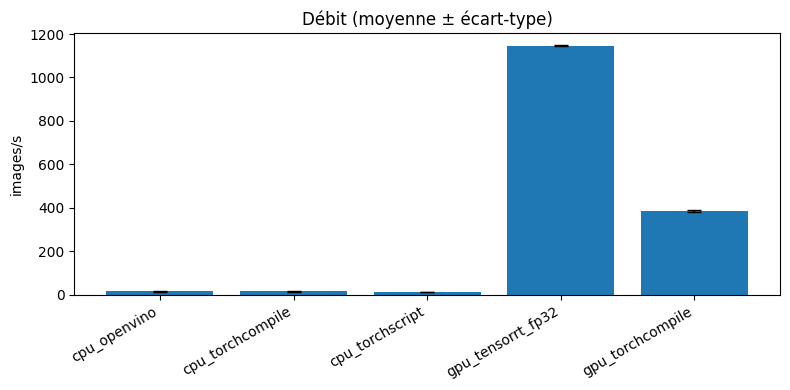

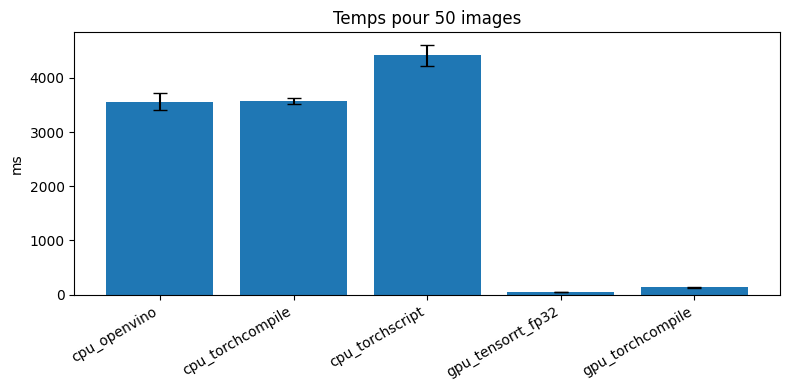

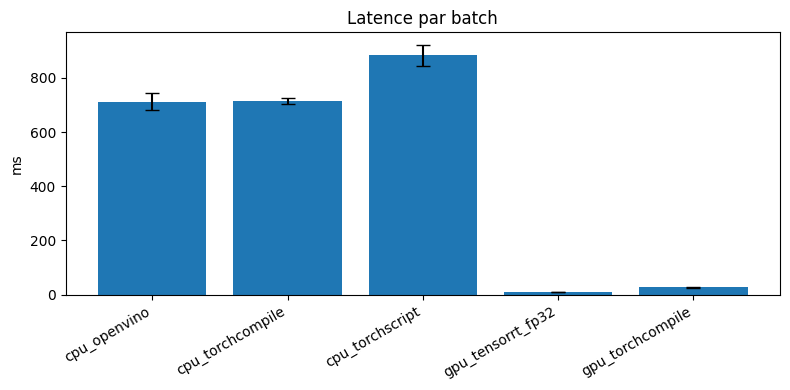

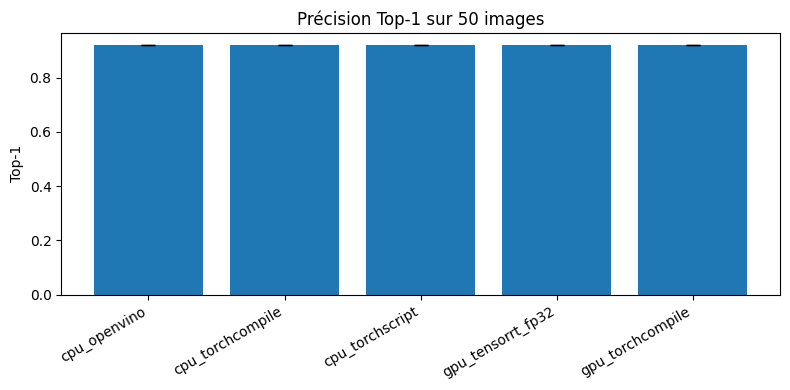

In [2]:
def bar(metric, ylabel, title, scale=1):
    m = [R[n]['summary'][metric]['mean'] * scale for n in names]
    s = [R[n]['summary'][metric]['std'] * scale for n in names]
    plt.figure(figsize=(8, 4)); plt.bar(names, m, yerr=s, capsize=5)
    plt.ylabel(ylabel); plt.title(title); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

bar('throughput', 'images/s', 'Débit (moyenne ± écart-type)')
bar('total_s', 'ms', 'Temps pour 50 images', scale=1000)
bar('batch_ms', 'ms', 'Latence par batch', scale=1)
bar('top1', 'Top-1', 'Précision Top-1 sur 50 images')

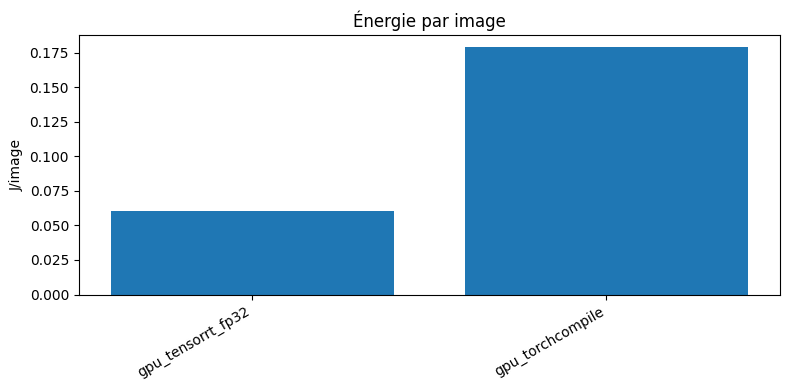

{'gpu_tensorrt_fp32': 65.8, 'gpu_torchcompile': 67.6} (W moyens)


In [3]:
e = [n for n in names if R[n]['energy']]
if e:
    plt.figure(figsize=(8, 4))
    plt.bar(e, [R[n]['energy']['joules_per_image'] for n in e]); plt.ylabel('J/image')
    plt.title('Énergie par image'); plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()
    print({n: round(R[n]['energy']['watts'], 1) for n in e}, '(W moyens)')
else:
    print('Aucune mesure énergétique disponible')

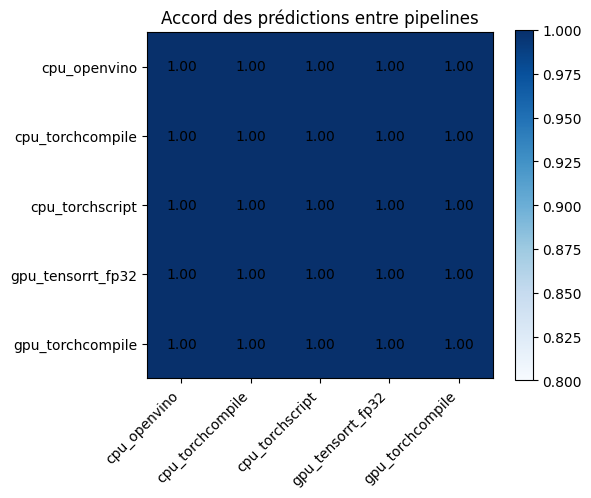

In [4]:
P = np.array([R[n]['preds'] for n in names])
A = np.array([[np.mean(P[i] == P[j]) for j in range(len(names))] for i in range(len(names))])
plt.figure(figsize=(6, 5)); plt.imshow(A, vmin=0.8, vmax=1, cmap='Blues'); plt.colorbar()
plt.xticks(range(len(names)), names, rotation=45, ha='right'); plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, f'{A[i,j]:.2f}', ha='center', va='center')
plt.title("Accord des prédictions entre pipelines"); plt.tight_layout(); plt.show()